# PASSAGE Sample Visualization

This notebook loads a tensor file generated by PASSAGE and displays it as an image with associated metadata.

**Tensor format:** `(H, W, 3)` with channels:
- Channel 0: Normalized elevation `[0, 1]`
- Channel 1: Marker positions (binary)
- Channel 2: Obstacles mask (binary; 1=blocked)

**Path data:** Stored in `metadata.yaml` under `paths.without_obstacles` and `paths.with_obstacles`.

**Obstacle settings:** Stored in `metadata.yaml` under `obstacles`.

**Solver details:** Stored in `metadata.yaml` under `solver` (includes `backend` and `cost_model`).

In [ ]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from loguru import logger as loguru_logger
from matplotlib.lines import Line2D

# Add src to path for imports
sys.path.insert(0, str(Path("../src").resolve()))
from passage.generate import tensor_to_image

# Configure info logging
logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(name)s - %(levelname)s - %(message)s")
logger = logging.getLogger(__name__)
logger.setLevel(logging.INFO)

# Configure loguru for info level
loguru_logger.remove()
loguru_logger.add(sys.stderr, level="INFO")

## Configuration

Set the resolution and sample index to visualize.

In [2]:
# Configuration
RESOLUTION = 256  # Resolution: 64, 128, 256, 512, 1024, 2048, 4096
SAMPLE_INDEX = 0  # Sample index to visualize

# Build paths
tensor_path = Path(f"../outputs/dataset/{RESOLUTION}/tensors/{SAMPLE_INDEX:010d}.npy")
metadata_path = Path(f"../outputs/dataset/{RESOLUTION}/metadata/{SAMPLE_INDEX:010d}.yaml")

print(f"Tensor path:   {tensor_path}")
print(f"Metadata path: {metadata_path}")
print(f"Tensor exists: {tensor_path.exists()}")
print(f"Metadata exists: {metadata_path.exists()}")

Tensor path:   ../outputs/dataset/256/tensors/0000000000.npy
Metadata path: ../outputs/dataset/256/metadata/0000000000.yaml
Tensor exists: True
Metadata exists: True


## Load Tensor and Metadata

In [3]:
# Load tensor
tensor = np.load(tensor_path)
print(f"Tensor shape: {tensor.shape}")
print(f"Tensor dtype: {tensor.dtype}")

# Load metadata
with open(metadata_path) as f:
    metadata = yaml.safe_load(f)

print(f"\nSample index: {metadata['index']}")
print(f"Resolution: {metadata['resolution']}x{metadata['resolution']}")

Tensor shape: (256, 256, 3)
Tensor dtype: float32

Sample index: 0
Resolution: 256x256


## Display Metadata

In [4]:
print("=" * 60)
print("SAMPLE METADATA")
print("=" * 60)

# Source tile info
tile_info = metadata.get("tile", {})
source_tile = tile_info.get("source", {})
crop_info = metadata.get("crop", {})
center = crop_info.get("center", {})
center_lat = center.get("lat")
center_lon = center.get("lon")
print(f"\n📍 Source Tile: {source_tile.get('name', 'N/A')}")
if center_lat is not None and center_lon is not None:
    print(f"   Center: ({center_lat:.4f}°, {center_lon:.4f}°)")
else:
    print("   Center: (N/A, N/A)")

# Elevation info
print("\n🏔️  Elevation:")
print(f"   Target: {metadata.get('target_elevation', float('nan')):.1f} m")
crop_min = crop_info.get("min_elevation")
crop_max = crop_info.get("max_elevation")
tile_stats = tile_info.get("stats", {})
tile_min = tile_stats.get("min_elevation")
tile_max = tile_stats.get("max_elevation")
if crop_min is not None and crop_max is not None:
    print(f"   Crop range: [{crop_min:.1f}, {crop_max:.1f}] m")
if tile_min is not None and tile_max is not None:
    print(f"   Tile range: [{tile_min:.1f}, {tile_max:.1f}] m")

# Markers info
markers = metadata.get("markers", {})
start_point = markers.get("start_point", {})
end_point = markers.get("end_point", {})
print("\n📌 Markers:")
print(
    f"   Start: ({start_point.get('i', 'N/A')}, {start_point.get('j', 'N/A')}) at {start_point.get('elevation', float('nan')):.1f} m"
)
print(
    f"   End:   ({end_point.get('i', 'N/A')}, {end_point.get('j', 'N/A')}) at {end_point.get('elevation', float('nan')):.1f} m"
)

# Path info
paths = metadata.get("paths", {})
path_wo = paths.get("without_obstacles") or metadata.get("path", {})
path_w = paths.get("with_obstacles", {})
print("\n🛤️  Paths:")
print(f"   Without obstacles: {path_wo.get('length', 'N/A')} pixels")
print(f"   With obstacles:    {path_w.get('length', 'N/A')} pixels")

# Obstacles info
obstacles_info = metadata.get("obstacles", {})
print("\n🧱 Obstacles:")
print(f"   Enabled: {obstacles_info.get('enabled', 'N/A')}")
print(f"   Ratio target: {obstacles_info.get('ratio_target', 'N/A')}")
print(f"   Ratio actual: {obstacles_info.get('ratio_actual', 'N/A')}")

# Solver info
solver_info = metadata.get("solver", {})
print("\n⚙️  Solver:")
print(f"   Backend: {solver_info.get('backend', 'N/A')}")
print(f"   Algorithm: {solver_info.get('name', 'N/A')}")
print(f"   Diagonal: {solver_info.get('diagonal_movement', 'N/A')}")
print(f"   Weight: {solver_info.get('weight', 'N/A')}")
print(f"   Cost model: {solver_info.get('cost_model', 'N/A')}")
print(f"   Heuristic: {solver_info.get('heuristic', 'N/A')}")

# Timestamp
print(f"\n⏰ Generated: {metadata.get('timestamp', 'N/A')}")

SAMPLE METADATA

📍 Source Tile: N029W119
   Center: (29.1628°, -118.3189°)

🏔️  Elevation:
   Target: 1001.0 m
   Crop range: [-1.0, 1260.0] m
   Tile range: [-2.0, 1290.0] m

📌 Markers:
   Start: (159, 89) at 1001.0 m
   End:   (78, 215) at 0.0 m

🛤️  Paths:
   Without obstacles: 149 pixels
   With obstacles:    149 pixels

🧱 Obstacles:
   Enabled: True
   Ratio target: 0.06819627894017921
   Ratio actual: 0.0636749267578125

⚙️  Solver:
   Backend: grid
   Algorithm: grid_astar
   Diagonal: always
   Weight: 100.0
   Cost model: energy
   Heuristic: euclidean

⏰ Generated: 2026-01-19T16:29:44.684989


## Visualize Sample Image

Convert tensor to image using `tensor_to_image` with path from metadata.

Path pixels: 149 points


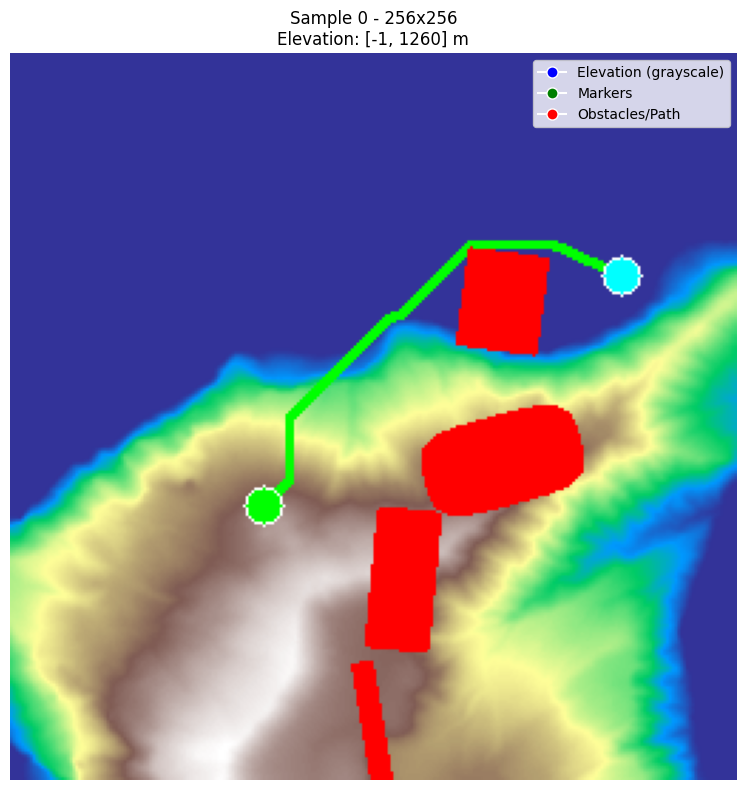

In [ ]:
# Build path pixels from metadata
paths = metadata.get("paths", {})
use_obstacles = bool(metadata.get("obstacles", {}).get("enabled", False))
path_section = paths.get("with_obstacles") if use_obstacles else paths.get("without_obstacles")
if path_section is None:
    path_section = metadata.get("path", {})
path_pixels = [(p["i"], p["j"]) for p in path_section.get("pixels", [])]
print(f"Path pixels: {len(path_pixels)} points")

# Convert tensor to BGR image
bgr_image = tensor_to_image(tensor, path_pixels=path_pixels)

# Convert BGR to RGB for matplotlib
rgb_image = bgr_image[:, :, ::-1]

# Display
crop_info = metadata.get("crop", {})
crop_min = crop_info.get("min_elevation", float("nan"))
crop_max = crop_info.get("max_elevation", float("nan"))

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(rgb_image, origin="upper")
ax.set_title(
    f"Sample {metadata['index']} - {metadata['resolution']}x{metadata['resolution']}\nElevation: [{crop_min:.0f}, {crop_max:.0f}] m"
)
ax.axis("off")

# Add legend

legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="blue", markersize=8, label="Elevation (grayscale)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="green", markersize=8, label="Markers"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="red", markersize=8, label="Obstacles/Path"),
]
ax.legend(handles=legend_elements, loc="upper right")
plt.tight_layout()
plt.show()

## Individual Channels

Visualize elevation and marker channels separately.

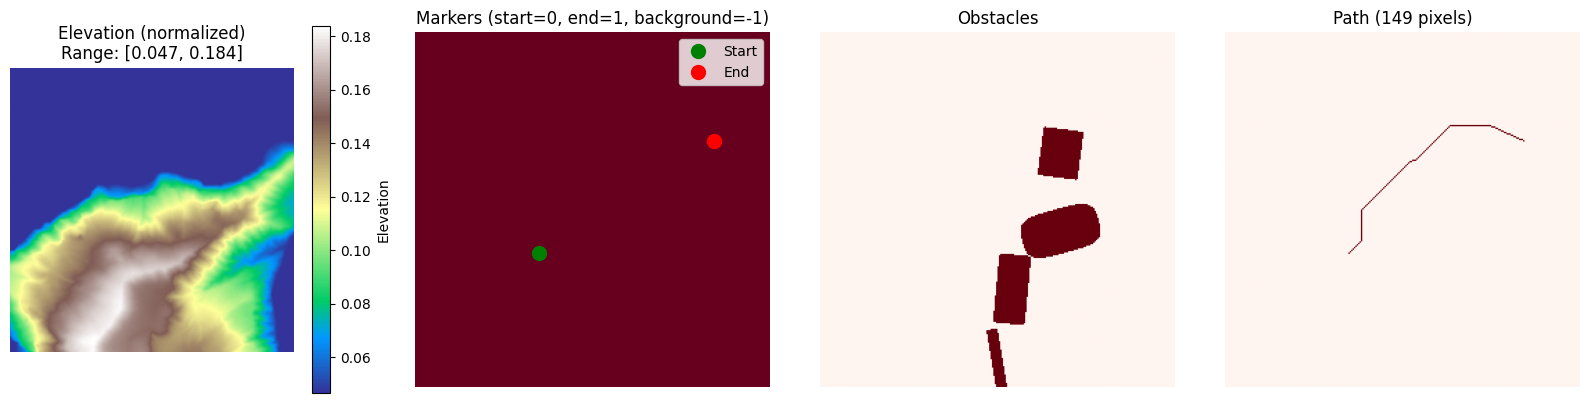

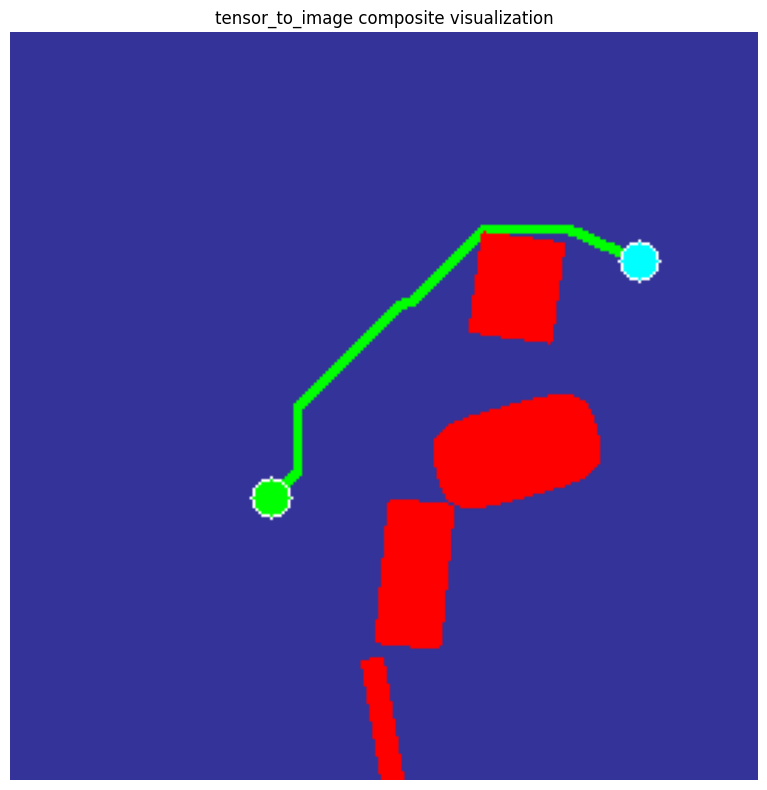

In [6]:
# Extract channels
elevation = tensor[:, :, 0]
markers_ch = tensor[:, :, 1]
obstacles_ch = tensor[:, :, 2] if tensor.shape[2] > 2 else np.zeros_like(elevation)

# Create path channel from metadata
paths = metadata.get("paths", {})
use_obstacles = bool(metadata.get("obstacles", {}).get("enabled", False))
path_section = paths.get("with_obstacles") if use_obstacles else paths.get("without_obstacles")
if path_section is None:
    path_section = metadata.get("path", {})
path_pixels = [(p["i"], p["j"]) for p in path_section.get("pixels", [])]
path_ch = np.zeros_like(elevation, dtype=np.float32)
for pi, pj in path_pixels:
    path_ch[pi, pj] = 1.0

# Create figure
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Elevation
im0 = axes[0].imshow(elevation, cmap="terrain", origin="upper")
axes[0].set_title(f"Elevation (normalized)\nRange: [{elevation.min():.3f}, {elevation.max():.3f}]")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], label="Elevation")

# Markers
im1 = axes[1].imshow(markers_ch, cmap="RdBu", vmin=-1, vmax=1, origin="upper")
axes[1].set_title("Markers (start=0, end=1, background=-1)")
start_positions = np.argwhere(np.isclose(markers_ch, 0.0))
end_positions = np.argwhere(markers_ch > 0.5)
if len(start_positions) > 0:
    axes[1].plot(start_positions[:, 1], start_positions[:, 0], "o", color="green", markersize=10, label="Start")
if len(end_positions) > 0:
    axes[1].plot(end_positions[:, 1], end_positions[:, 0], "o", color="red", markersize=10, label="End")
axes[1].legend()
axes[1].axis("off")

# Obstacles
im2 = axes[2].imshow(obstacles_ch, cmap="Reds", vmin=0, vmax=1, origin="upper")
axes[2].set_title("Obstacles")
axes[2].axis("off")

# Path
im3 = axes[3].imshow(path_ch, cmap="Reds", vmin=0, vmax=1, origin="upper")
axes[3].set_title(f"Path ({len(path_pixels)} pixels)")
axes[3].axis("off")

plt.tight_layout()
plt.show()

# Create a full visualization using tensor_to_image (external extraction of path pixels and elevation bounds)
try:
    crop_info = metadata.get("crop", {})
    elev_range = (
        (crop_info.get("min_elevation"), crop_info.get("max_elevation"))
        if "min_elevation" in crop_info and "max_elevation" in crop_info
        else None
    )
except Exception:
    elev_range = None

tensor_vis = np.stack([elevation, markers_ch, obstacles_ch], axis=-1)
# pass path_pixels explicitly
bgr_image = tensor_to_image(tensor_vis, path_pixels=path_pixels, elev_range=elev_range)

fig2, ax2 = plt.subplots(figsize=(8, 8))
ax2.imshow(bgr_image[:, :, ::-1], origin="upper")
ax2.set_title("tensor_to_image composite visualization")
ax2.axis("off")
plt.tight_layout()
plt.show()

## Elevation Profile Along Path

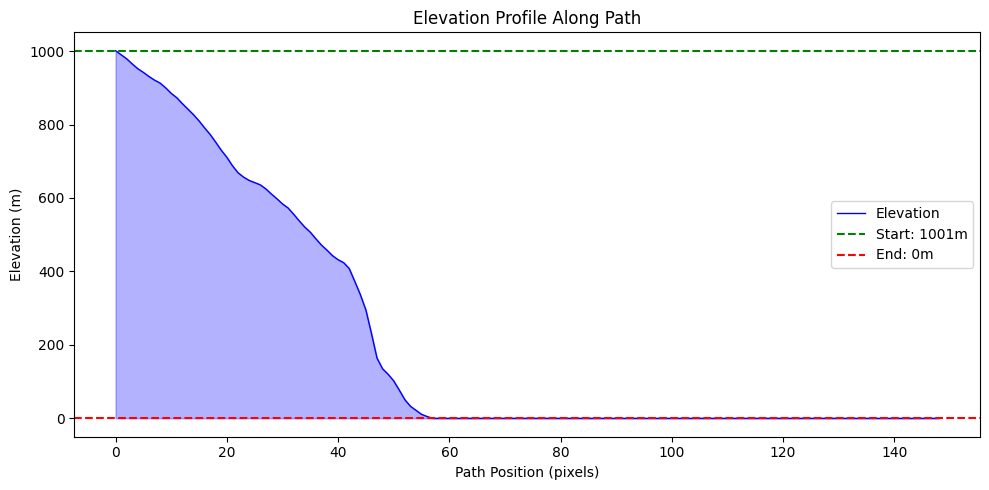

Path elevation stats:
  Min: -0.0 m
  Max: 1001.0 m
  Mean: 218.0 m
  Total climb: 0.0 m


In [7]:
if len(path_pixels) > 0:
    # Get elevation values along path (denormalize using crop range)
    calib_info = metadata.get("calibration", {})
    calib_min = calib_info.get("min", None)
    calib_max = calib_info.get("max", None)

    path_elevations = []
    for pi, pj in path_pixels:
        norm_elev = elevation[pi, pj]
        if calib_min is not None and calib_max is not None:
            real_elev = float(norm_elev) * (calib_max - calib_min) + calib_min
        else:
            real_elev = float(norm_elev)
        path_elevations.append(real_elev)

    # Plot profile
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(path_elevations, "b-", linewidth=1, label="Elevation")
    ax.fill_between(range(len(path_elevations)), path_elevations, alpha=0.3, color="blue")

    # Mark start and end
    markers = metadata.get("markers", {})
    start_point = markers.get("start_point", {})
    end_point = markers.get("end_point", {})
    if "elevation" in start_point:
        ax.axhline(
            y=start_point["elevation"], linestyle="--", color="green", label=f"Start: {start_point['elevation']:.0f}m"
        )
    if "elevation" in end_point:
        ax.axhline(y=end_point["elevation"], linestyle="--", color="red", label=f"End: {end_point['elevation']:.0f}m")

    ax.set_xlabel("Path Position (pixels)")
    ax.set_ylabel("Elevation (m)")
    ax.set_title("Elevation Profile Along Path")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Statistics
    print("Path elevation stats:")
    print(f"  Min: {min(path_elevations):.1f} m")
    print(f"  Max: {max(path_elevations):.1f} m")
    print(f"  Mean: {np.mean(path_elevations):.1f} m")
    print(
        f"  Total climb: {sum(max(0, path_elevations[i + 1] - path_elevations[i]) for i in range(len(path_elevations) - 1)):.1f} m"
    )
else:
    print("No path data available")